# Step 4a Inspect the MNIST workload

Before running digit recognition on our accelerator, inspect the images it will
use. This increment loads **10,000 handwritten-digit test images**, checks their
files, and shows how each image becomes 784 input numbers.

In Colab, choose **Runtime → Run all**. The notebook downloads about **1.65 MB**
on the first run. It uses NumPy and Matplotlib from the standard Colab environment.
No earlier notebook, repository setup, GPU, or Drive mount is needed.

The final cell should finish with **All 6 MNIST data checks passed.**


## 1 Images and known answers

MNIST contains small grayscale pictures of handwritten digits. Each picture is
**28 × 28 pixels**. Its **label** is the known digit, from 0 through 9.

The label is the answer we will later compare with the network's prediction.
This increment displays those known labels. Prediction code comes next.

The downloaded files contain pixel values and labels in a compact binary format
called IDX. The loader below checks file identity before decoding their headers
and contents. The checksum is a fingerprint of the published file.


In [1]:
import gzip
import hashlib
from pathlib import Path
import struct
import sys
import unittest
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

CACHE = Path("mnist-cache")
MIRROR = "https://ossci-datasets.s3.amazonaws.com/mnist/"
TEST_FILES = {
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}


def check_file_identity(payload, expected_md5):
    if hashlib.md5(payload).hexdigest() != expected_md5:
        raise ValueError("MNIST file checksum does not match the published file.")
    return payload


def fetch_test_file(filename):
    CACHE.mkdir(exist_ok=True)
    path = CACHE / filename
    if path.exists():
        payload = check_file_identity(path.read_bytes(), TEST_FILES[filename])
    else:
        print("Downloading", filename)
        with urllib.request.urlopen(MIRROR + filename, timeout=30) as response:
            payload = check_file_identity(response.read(), TEST_FILES[filename])
        path.write_bytes(payload)
    return payload


def normalize_pixels(pixels):
    return pixels.astype(np.float32) / np.float32(255)



def decode_images(payload):
    if len(payload) < 16:
        raise ValueError("Truncated image header.")
    magic, count, height, width = struct.unpack(">IIII", payload[:16])
    if magic != 2051 or (height, width) != (28, 28) or count < 1:
        raise ValueError("Invalid MNIST image header.")
    if len(payload) != 16 + count * height * width:
        raise ValueError("Image payload length does not match its header.")
    return np.frombuffer(payload, dtype=np.uint8, offset=16).reshape(count, 784)


def decode_labels(payload):
    if len(payload) < 8:
        raise ValueError("Truncated label header.")
    magic, count = struct.unpack(">II", payload[:8])
    if magic != 2049 or count < 1 or len(payload) != 8 + count:
        raise ValueError("Invalid MNIST label file.")
    labels = np.frombuffer(payload, dtype=np.uint8, offset=8)
    if np.any(labels > 9):
        raise ValueError("MNIST labels must be digits 0 through 9.")
    return labels

print("Verified MNIST loader ready.")


Verified MNIST loader ready.


## 2 Load the test set

Each original pixel is an integer from **0 to 255**: black through white. Dividing
by 255 represents that pixel on a **0 to 1** scale for the future network input.

A 28 × 28 picture contains `28 × 28 = 784` pixels. The loader stores each picture
as one row of 784 values. The same values can be reshaped into a picture again.

These files are the held-out test set. Later training and calibration will use
separate data, so the test labels remain a fair accuracy check.


In [2]:
image_file = fetch_test_file("t10k-images-idx3-ubyte.gz")
label_file = fetch_test_file("t10k-labels-idx1-ubyte.gz")
pixels = decode_images(gzip.decompress(image_file))
labels = decode_labels(gzip.decompress(label_file))
if pixels.shape != (10000, 784) or labels.shape != (10000,):
    raise ValueError("Expected 10,000 images with 784 pixels and one label each.")
inputs = normalize_pixels(pixels)
print("Images:", len(inputs))
print("Input table shape:", inputs.shape)
print("Labels:", len(labels))
print("Original pixel type:", pixels.dtype)
print("Normalized input type:", inputs.dtype)
print("Original pixel range:", int(pixels.min()), "to", int(pixels.max()))
print("Normalized range:", float(inputs.min()), "to", float(inputs.max()))


Images: 10000
Input table shape: (10000, 784)
Labels: 10000
Original pixel type: uint8
Normalized input type: float32
Original pixel range: 0 to 255
Normalized range: 0.0 to 1.0


## 3 Look at the images

These are the first twelve test images. Each title shows the label supplied with
the dataset. It is a known answer, not a guess made by our program.


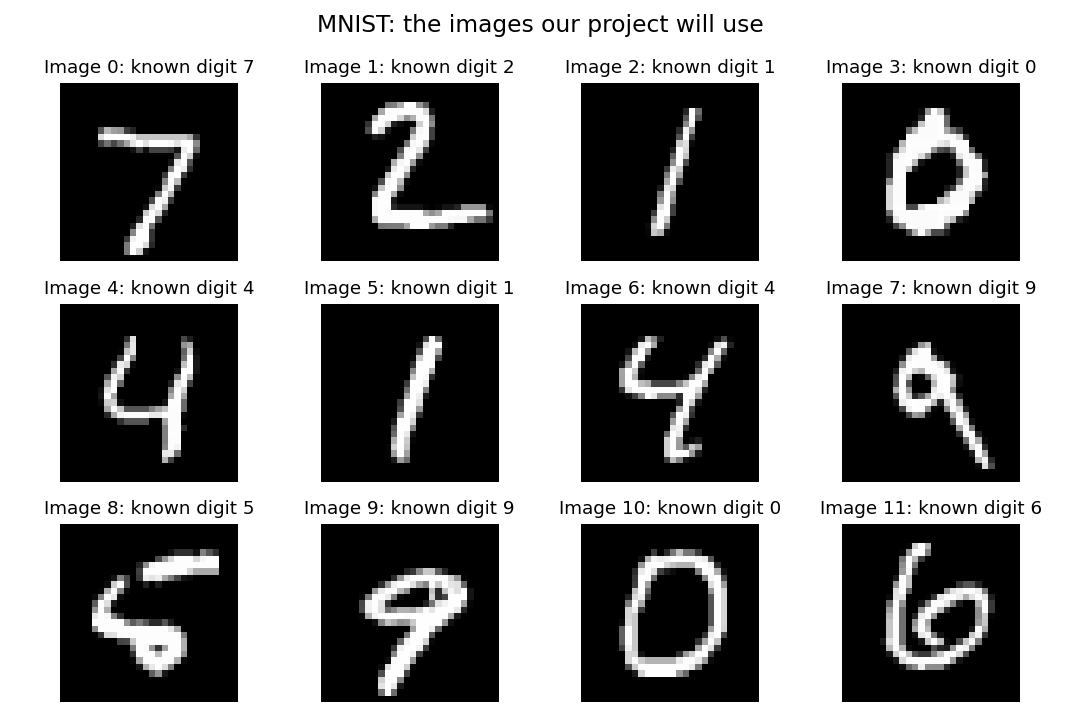

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(9, 6))
for index, ax in enumerate(axes.flat):
    ax.imshow(inputs[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Image {index}: known digit {labels[index]}", fontsize=11)
    ax.axis("off")
fig.suptitle("MNIST: the images our project will use", fontsize=14)
fig.tight_layout()
plt.show()


## 4 Connect one picture to its numbers

Change `image_index` to another value from 0 through 9999 and rerun the next cell
to inspect a different image. A network will receive these pixel numbers and
calculate ten scores, one for each digit. We will add that calculation next.


In [4]:
image_index = 0
if not 0 <= image_index < len(inputs):
    raise ValueError("image_index must be between 0 and 9999.")
picture = inputs[image_index].reshape(28, 28)
print("Image index:", image_index)
print("Known digit:", int(labels[image_index]))
print("Picture shape:", picture.shape)
print("Network input shape:", inputs[image_index:image_index + 1].shape)
print("Pixels above zero:", int(np.count_nonzero(picture)))
print("Middle row, rounded for display:")
print(np.round(picture[14], 2))


Image index: 0
Known digit: 7
Picture shape: (28, 28)
Network input shape: (1, 784)
Pixels above zero: 116
Middle row, rounded for display:
[0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.23 0.98 1.   0.24 0.   0.   0.   0.   0.   0.   0.   0.  ]


## 5 Check that the data was read correctly

The checks cover valid and malformed image records, valid and invalid labels,
checksum rejection, known pixel normalization, and the real test-set dimensions.
They use small invented records as well as the actual downloaded data.


In [5]:
class MnistDataTests(unittest.TestCase):
    def test_known_image_record(self):
        record = struct.pack(">IIII", 2051, 1, 28, 28) + bytes([255] * 784)
        decoded = decode_images(record)
        self.assertEqual(decoded.shape, (1, 784))
        self.assertEqual(decoded.dtype, np.uint8)
        self.assertTrue(np.all(decoded == 255))

    def test_reject_malformed_image_records(self):
        valid = struct.pack(">IIII", 2051, 1, 28, 28) + bytes(784)
        for record in (b"", valid[:-1], struct.pack(">IIII", 0, 1, 28, 28) + bytes(784)):
            with self.subTest(size=len(record)), self.assertRaises(ValueError):
                decode_images(record)

    def test_known_labels_and_reject_bad_records(self):
        valid = struct.pack(">II", 2049, 2) + bytes([3, 7])
        self.assertEqual(decode_labels(valid).tolist(), [3, 7])
        for record in (b"", valid[:-1], struct.pack(">II", 2049, 1) + bytes([10])):
            with self.subTest(size=len(record)), self.assertRaises(ValueError):
                decode_labels(record)

    def test_checksum_rejects_changed_content(self):
        expected = "5d41402abc4b2a76b9719d911017c592"
        self.assertEqual(check_file_identity(b"hello", expected), b"hello")
        with self.assertRaises(ValueError):
            check_file_identity(b"changed", expected)

    def test_known_normalized_values(self):
        normalized = normalize_pixels(np.array([[0, 127, 255]], dtype=np.uint8))
        self.assertEqual(normalized.dtype, np.float32)
        np.testing.assert_allclose(normalized, [[0.0, 0.4980392156862745, 1.0]], rtol=1e-6)

    def test_real_test_set_shape_and_labels(self):
        self.assertEqual(inputs.shape, (10000, 784))
        self.assertEqual(labels.shape, (10000,))
        self.assertTrue(np.all((labels >= 0) & (labels <= 9)))
        self.assertEqual(int(labels[0]), 7)
        self.assertEqual(int(labels[8]), 5)
        self.assertGreaterEqual(float(inputs.min()), 0)
        self.assertLessEqual(float(inputs.max()), 1)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(MnistDataTests)
result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
if not result.wasSuccessful():
    raise AssertionError("A data check failed; review the output above.")
print(f"All {result.testsRun} MNIST data checks passed.")


test_checksum_rejects_changed_content (__main__.MnistDataTests.test_checksum_rejects_changed_content) ... ok
test_known_image_record (__main__.MnistDataTests.test_known_image_record) ... ok
test_known_labels_and_reject_bad_records (__main__.MnistDataTests.test_known_labels_and_reject_bad_records) ... ok
test_known_normalized_values (__main__.MnistDataTests.test_known_normalized_values) ... ok
test_real_test_set_shape_and_labels (__main__.MnistDataTests.test_real_test_set_shape_and_labels) ... ok
test_reject_malformed_image_records (__main__.MnistDataTests.test_reject_malformed_image_records) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.029s

OK
All 6 MNIST data checks passed.


## Next increment

We now have verified images, known labels, and correctly shaped input numbers.
Next we will add the **FP32 prediction baseline**: feed an image into the network,
show its guessed digit, and count correct predictions. INT8 quantization and
accelerator timing follow in separate increments.

**Dataset identities and mirror reference:**
[https://github.com/pytorch/vision/blob/main/torchvision/datasets/mnist.py](https://github.com/pytorch/vision/blob/main/torchvision/datasets/mnist.py).
The loader uses NumPy and the standard library; it does not import torchvision.
